In [2]:


print("Multiclass Network Intrusion Detection")
print("Dataset: CICIDS2017")
print("Objective: Identify different types of network traffic")

Multiclass Network Intrusion Detection
Dataset: CICIDS2017
Objective: Identify different types of network traffic


In [3]:
# Step 2: Import Required Libraries

# Data handling
import os
import zipfile
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [4]:
# Step 3: Upload the Original CICIDS2017 Dataset

from google.colab import files

uploaded = files.upload()

Saving MachineLearningCSV.zip to MachineLearningCSV.zip


In [5]:
# Step 4: Extract the Original CICIDS2017 Dataset

# Import the os library.
# WHY: It helps us create folders, list files, and manage paths.
import os

# Import the zipfile library.
# WHY: It allows Python to extract files from a ZIP archive.
import zipfile

# Find the uploaded ZIP filename automatically.
# WHY: This avoids manually typing the filename incorrectly.
zip_files = [filename for filename in uploaded.keys()
             if filename.lower().endswith('.zip')]

# Check that a ZIP file was uploaded before extracting it.
# WHY: This prevents an error if the upload was unsuccessful.
if len(zip_files) == 0:
    print("Error: No ZIP file found. Please upload the dataset ZIP.")
else:
    # Store the uploaded ZIP filename.
    zip_path = zip_files[0]

    # Create a folder to store the extracted dataset.
    # WHY: Keeping the files in one folder makes them easier to manage.
    extract_path = "/content/CICIDS2017"
    os.makedirs(extract_path, exist_ok=True)

    # Open the ZIP file in read mode.
    # WHY: We need access to the archived CSV files.
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:

        # Extract all files into the designated folder.
        # WHY: The CSV files must be extracted before pandas can read them.
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully!")
    print("Extraction folder:", extract_path)

    # Display the extracted folder's contents.
    # WHY: This verifies that extraction completed and shows
    # us where the dataset files are stored.
    print("\nExtracted contents:")
    print(os.listdir(extract_path))

Dataset extracted successfully!
Extraction folder: /content/CICIDS2017

Extracted contents:
['MachineLearningCVE']


In [6]:

# Step 4.1: Locate the CSV Files

# Search the extracted dataset folder and its subfolders.
# WHY: The CSV files may be stored inside nested folders.
csv_files = []

for root, directories, files_in_folder in os.walk("/content/CICIDS2017"):
    for filename in files_in_folder:

        # Select only CSV files, ignoring filename capitalization.
        # WHY: We need the CSV files containing network traffic records.
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

# Display the number and names of the CSV files found.
# WHY: This confirms the dataset was extracted correctly and
# helps us verify which files will be loaded.
print("Number of CSV files found:", len(csv_files))

print("\nCSV file paths:")
for file_path in csv_files:
    print(file_path)

Number of CSV files found: 8

CSV file paths:
/content/CICIDS2017/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/content/CICIDS2017/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv


We do this step to find all the CSV files inside the extracted CICIDS2017 dataset before loading them into Python.

 Dataset ZIP contains multiple CSV files, each representing different network traffic records. We need to identify them so we can combine them and classify the original attack types.

In [7]:
#
# Step 4.2: Load and Combine the CSV Files

# Create an empty list to store the DataFrames.
# WHY: Each CSV file will be loaded separately before combining.
dataframes = []

# Read each CSV file found in Step 4.1.
for file_path in csv_files:

    # Load the CSV file into a pandas DataFrame.
    # WHY: DataFrames allow us to inspect and process tabular data.
    temp_df = pd.read_csv(file_path, low_memory=False)

    # Store the loaded DataFrame in the list.
    # WHY: We will combine all files after loading them.
    dataframes.append(temp_df)

    # Display the file name and its number of records.
    # WHY: This helps us verify that each file was loaded.
    print(os.path.basename(file_path), "->", temp_df.shape)

# Combine all DataFrames into one dataset.
# WHY: A single dataset makes it easier to analyse all traffic classes.
# ignore_index=True creates a fresh sequential row index.
df = pd.concat(dataframes, ignore_index=True)

# Display the combined dataset dimensions.
# WHY: The shape tells us the total number of records and columns.
print("\nCombined dataset shape:", df.shape)

Wednesday-workingHours.pcap_ISCX.csv -> (692703, 79)
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv -> (225745, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv -> (191033, 79)
Tuesday-WorkingHours.pcap_ISCX.csv -> (445909, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv -> (286467, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv -> (288602, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv -> (170366, 79)
Monday-WorkingHours.pcap_ISCX.csv -> (529918, 79)

Combined dataset shape: (2830743, 79)


Before preprocessing, we need to know the column names, data types, and original attack labels. This helps us avoid accidentally deleting useful features or losing individual attack categories.

In [8]:
# STEP 4.3: INITIAL DATASET INSPECTION

# 1. CHECK THE DATASET DIMENSIONS
# WHAT: Displays the total number of rows and columns.
# WHY: Helps us understand the size of the combined dataset.
print("Dataset shape:", df.shape)


# 2. DISPLAY THE FIRST FIVE ROWS
# WHAT: Shows the first five network traffic records.
# WHY: Helps us understand the structure and values of the data.
display(df.head())


# 3. DISPLAY ALL COLUMN NAMES
# WHAT: Prints the names of all columns in the dataset.
# WHY: Helps us identify the network traffic features and target label.
print("\nColumn names:")
print(df.columns.tolist())


# 4. CHECK DATA TYPES AND NON-NULL COUNTS
# WHAT: Shows each column's data type and number of non-missing values.
# WHY: Helps identify data type issues and potentially missing values.
print("\nDataset information:")
df.info()

Dataset shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,6,6,6.000000,0.000000,3.132505e+02,52.208416,38308.000000,0.000000,38308,38308,0,0.000000,0.000000,0,0,0,0.000000,0.000000,0,0,0,0,0,0,20,20,26.104208,26.104208,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,1,9.000000,6.000000,6.000000,20,0,0,0,0,0,0,1,6,1,6,255,946,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,163,0,65.200000,89.278777,1.039666e+06,33402.922760,31.933333,25.510409,73,0,479,47.900000,38.942836,109,1,401,100.250000,101.736178,237,3,0,0,0,0,368,176,22964.509390,10438.413360,0,163,29.294118,56.529599,3195.595588,0,0,0,1,0,0,0,0,0,31.125000,15.636364,65.200000,368,0,0,0,0,0,0,11,172,5,326,29200,260,4,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,1575,0,525.000000,813.326503,5.753425e+06,14611.872150,73.000000,204.960972,810,1,1095,121.666667,298.746130,915,1,995,199.000000,345.535092,810,3,0,0,0,0,336,208,9132.420091,5479.452055,0,1575,370.588235,671.751541,451250.132400,0,0,0,1,0,0,0,0,0,393.750000,315.000000,525.000000,336,0,0,0,0,0,0,10,3150,6,3150,29200,2081,3,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,3069,0,555.000000,977.480342,6.650007e+05,1907.141918,543.071429,2519.931377,13391,0,15206,950.375000,3322.417812,13391,2,15112,1373.818182,4176.449588,13961,3,0,0,0,0,560,388,1117.979745,789.162173,0,3069,337.066667,704.654082,496537.374700,0,0,0,1,0,0,0,0,0,348.689655,203.058823,555.000000,560,0,0,0,0,0,0,17,3452,12,6660,29200,0,10,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,1576,0,525.333333,813.842901,5.771062e+06,13736.263740,78.000000,207.000929,794,1,1092,136.500000,313.850738,910,1,1015,203.000000,333.240154,794,3,0,0,0,0,304,208,8241.758242,5494.505495,0,1576,393.875000,704.585067,496440.116700,0,0,0,1,0,0,0,0,0,420.133333,350.000000,525.333333,304,0,0,0,0,0,0,9,3150,6,3152,29200,2081,2,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



Column names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Coun

Exploratory Data Analysis (EDA).

In [9]:
# STEP 5.1: TARGET COLUMN AND CLASS DISTRIBUTION

# 1. REMOVE EXTRA SPACES FROM COLUMN NAMES
# WHAT: Removes leading and trailing spaces from column names.
# WHY: Some CICIDS2017 CSV files contain spaces in their headers.
# This helps us refer to columns consistently.
df.columns = df.columns.str.strip()


# 2. CHECK WHETHER THE TARGET COLUMN EXISTS
# WHAT: Checks for the column that contains the traffic labels.
# WHY: We need this column to train a supervised classification model.
if 'Label' in df.columns:

    # 3. COUNT RECORDS IN EACH ORIGINAL CLASS
    # WHAT: Counts the number of records for every label.
    # WHY: Reveals class imbalance and shows which attack types
    # are common or rare. We need this before choosing a strategy.
    class_counts = df['Label'].value_counts(dropna=False)

    print("Number of records in each class:")
    print(class_counts)

    # 4. COUNT THE NUMBER OF UNIQUE CLASSES
    # WHAT: Counts how many distinct labels exist.
    # WHY: Confirms the number of classes available for multiclass
    # classification before we decide how to group or retain them.
    print("\nNumber of unique classes:", df['Label'].nunique(dropna=False))

else:
    # Display a helpful message if the target column is missing.
    # WHY: We should investigate the column names rather than
    # continue with incorrect assumptions.
    print("Target column 'Label' was not found.")
    print("Available columns:", df.columns.tolist())

Number of records in each class:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Number of unique classes: 15


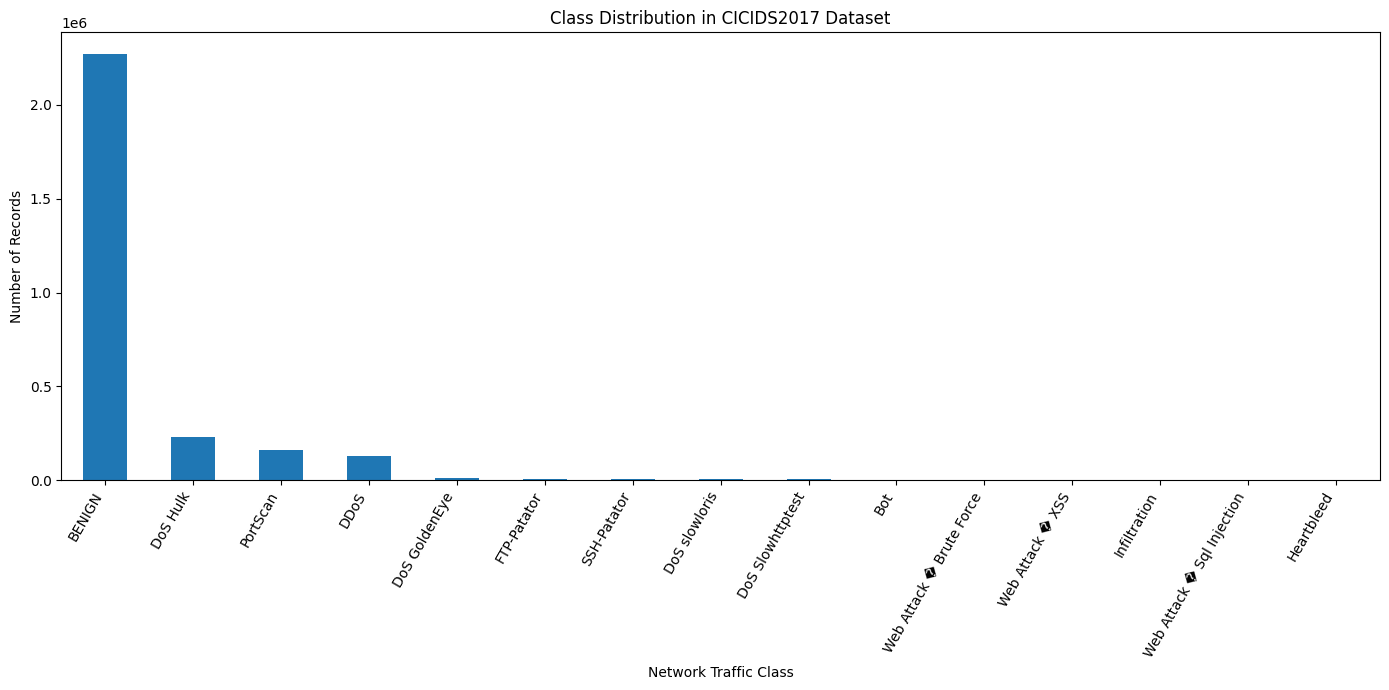

In [10]:
# STEP 5.2: CLASS DISTRIBUTION VISUALIZATION

# Count the records belonging to each original class.
# WHY: We need to understand the size of each class before
# deciding how to handle the imbalance.
class_counts = df['Label'].value_counts()

# Create a figure large enough to display all 15 class names.
# WHY: Some attack names are long and need enough space.
plt.figure(figsize=(14, 7))

# Draw a bar chart showing the number of records in each class.
# WHY: A visual comparison makes the imbalance easier to identify.
class_counts.plot(kind='bar')

# Add a descriptive title and axis labels.
# WHY: These make the chart suitable for analysis and reporting.
plt.title('Class Distribution in CICIDS2017 Dataset')
plt.xlabel('Network Traffic Class')
plt.ylabel('Number of Records')

# Rotate the class names so they do not overlap.
plt.xticks(rotation=60, ha='right')

# Adjust the layout so labels are not cut off.
plt.tight_layout()

# Display the chart.
plt.show()

In [11]:
# STEP 5.3: MISSING VALUES ANALYSIS

# 1. COUNT MISSING VALUES IN EACH COLUMN
# WHAT: Counts how many values are missing in every column.
# WHY: Missing values may affect model training and need
# to be investigated before preprocessing.
missing_counts = df.isnull().sum()

# 2. DISPLAY ONLY COLUMNS THAT CONTAIN MISSING VALUES
# WHAT: Filters the results to show columns with missing data.
# WHY: This makes it easier to identify which columns need attention.
missing_columns = missing_counts[missing_counts > 0]

print("Columns containing missing values:")
print(missing_columns)

# 3. CALCULATE THE TOTAL NUMBER OF MISSING VALUES
# WHAT: Adds all missing values across the dataset.
# WHY: Gives us an overall view of the amount of incomplete data.
print("\nTotal missing values:", df.isnull().sum().sum())

# 4. CALCULATE THE PERCENTAGE OF MISSING VALUES
# WHAT: Calculates the percentage of cells that are missing.
# WHY: Helps us judge whether missingness is limited or widespread.
total_cells = df.shape[0] * df.shape[1]
total_missing = df.isnull().sum().sum()
missing_percentage = (total_missing / total_cells) * 100

print(f"Percentage of missing values: {missing_percentage:.4f}%")

Columns containing missing values:
Flow Bytes/s    1358
dtype: int64

Total missing values: 1358
Percentage of missing values: 0.0006%


In [12]:
# STEP 5.4: INFINITE VALUES ANALYSIS

# 1. CHECK NUMERICAL COLUMNS FOR INFINITE VALUES
# WHAT: Identifies positive and negative infinity in numerical data.
# WHY: Infinite values can interfere with preprocessing and
# machine learning algorithms.
numeric_df = df.select_dtypes(include=np.number)

# Count infinite values in each numerical column.
# WHY: This identifies which features contain problematic values.
infinite_counts = np.isinf(numeric_df).sum()

# Display only columns that contain infinite values.
# WHY: Makes it easier to identify the features that need attention.
infinite_columns = infinite_counts[infinite_counts > 0]

print("Columns containing infinite values:")
print(infinite_columns)

# 2. CALCULATE THE TOTAL NUMBER OF INFINITE VALUES
# WHAT: Adds all positive and negative infinite values.
# WHY: Helps us understand the overall extent of the issue.
print("\nTotal infinite values:", infinite_counts.sum())

Columns containing infinite values:
Flow Bytes/s      1509
Flow Packets/s    2867
dtype: int64

Total infinite values: 4376


Why are we doing this?

Some network traffic features, such as Flow Bytes/s and Flow Packets/s, can contain infinite values due to calculations involving zero durations. These values can cause problems during model training, so we need to identify them.

In [13]:
# STEP 5.5: DUPLICATE RECORDS ANALYSIS

# Count rows that are exact duplicates of earlier rows.
# WHAT: Identifies repeated records across all columns.
# WHY: Duplicate records can affect model evaluation and may
# cause the model to learn repeated examples disproportionately.
duplicate_count = df.duplicated().sum()

# Display the total number of duplicate records.
# WHY: Helps us decide whether duplicate removal is necessary.
print("Total duplicate records:", duplicate_count)

# Calculate the percentage of duplicate records.
# WHY: Shows how much of the dataset consists of duplicates.
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Percentage of duplicate records: {duplicate_percentage:.2f}%")

Total duplicate records: 308381
Percentage of duplicate records: 10.89%


In [14]:
# STEP 5.6: DATA QUALITY SUMMARY

# Record the dataset size before cleaning.
# WHY: We need a baseline to measure how cleaning affects the data.
print("Original dataset shape:", df.shape)

# Count missing values across all columns.
# WHY: Missing values may require removal or imputation.
print("Total missing values:", df.isnull().sum().sum())

# Count infinite values in numerical columns.
# WHY: Infinite values must be handled before model training.
numeric_df = df.select_dtypes(include=np.number)
print("Total infinite values:", np.isinf(numeric_df).sum().sum())

# Count exact duplicate rows.
# WHY: Helps us quantify repeated records before deciding
# whether to remove them.
print("Total duplicate records:", df.duplicated().sum())

# Show the original distribution of target labels.
# WHY: We need to preserve a record of class counts so we can
# compare them after cleaning.
print("\nClass distribution before cleaning:")
print(df["Label"].value_counts())

Original dataset shape: (2830743, 79)
Total missing values: 1358
Total infinite values: 4376
Total duplicate records: 308381

Class distribution before cleaning:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


What does this mean?


Some network traffic records have identical values across all columns. Removing duplicates can reduce redundancy, but we must consider whether identical records represent repeated observations or legitimate recurring traffic.

We'll document the duplicate count and compare class distributions before and after removing duplicates. We'll also avoid splitting identical records across training and testing sets where possible.


In [15]:
# STEP 5.7: HANDLE MISSING AND INFINITE VALUES

# 1. REPLACE POSITIVE AND NEGATIVE INFINITY WITH MISSING VALUES
# WHAT: Converts infinite numerical values into NaN.
# WHY: Infinity can result from undefined calculations such as
# division by zero and can interfere with model training.
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2. COUNT ROWS CONTAINING MISSING VALUES
# WHAT: Counts rows with at least one missing value.
# WHY: Helps us understand how many records will be affected.
rows_with_missing = df.isnull().any(axis=1).sum()

print("Rows containing missing values:", rows_with_missing)

# 3. REMOVE ROWS CONTAINING MISSING VALUES
# WHAT: Removes records containing one or more missing values.
# WHY: The total missingness is very small, so removal is a
# practical initial choice. We will verify class counts afterward.
df.dropna(inplace=True)

# 4. VERIFY THE CLEANING RESULT
# WHAT: Displays the remaining missing values and dataset shape.
# WHY: Confirms whether the operation worked as expected.
print("\nDataset shape after handling missing values:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Rows containing missing values: 2867

Dataset shape after handling missing values: (2827876, 79)
Remaining missing values: 0


In [16]:
# STEP 5.8: DUPLICATE ANALYSIS BY CLASS

# 1. IDENTIFY DUPLICATE ROWS
# WHAT: Marks rows that exactly match an earlier row across
# all columns, including the original Label.
# WHY: We need to understand repeated records before removing them.
duplicate_mask = df.duplicated(keep='first')

# 2. COUNT DUPLICATES BY THEIR LABEL
# WHAT: Counts the labels of duplicate rows.
# WHY: Shows which classes contribute most to the duplicate records.
duplicate_labels = df.loc[duplicate_mask, 'Label'].value_counts()

print("Duplicate records by class:")
print(duplicate_labels)

# 3. COMPARE THE NUMBER OF RECORDS BEFORE REMOVAL
# WHAT: Displays the current dataset size and duplicate count.
# WHY: Provides a baseline for checking the effect of removal.
print("\nDataset shape before duplicate removal:", df.shape)
print("Total duplicate rows:", duplicate_mask.sum())

Duplicate records by class:
Label
BENIGN                      176263
PortScan                     68110
DoS Hulk                     57278
SSH-Patator                   2678
FTP-Patator                   2004
DoS slowloris                  411
DoS Slowhttptest               271
Web Attack � Brute Force        37
DDoS                            11
Bot                              8
DoS GoldenEye                    7
Name: count, dtype: int64

Dataset shape before duplicate removal: (2827876, 79)
Total duplicate rows: 307078


In [17]:
# STEP 5.9: REMOVE EXACT DUPLICATE RECORDS

# 1. STORE THE ROW COUNT BEFORE REMOVAL
# WHAT: Records the current number of rows.
# WHY: We need to measure how many records are removed.
rows_before = len(df)

# 2. REMOVE EXACT DUPLICATE ROWS
# WHAT: Keeps the first occurrence of each identical row.
# WHY: Reduces repeated records that could disproportionately
# influence model training.
df.drop_duplicates(inplace=True)

# 3. COUNT ROWS AFTER REMOVAL
# WHAT: Measures the remaining dataset size.
# WHY: Confirms the effect of duplicate removal.
rows_after = len(df)

# 4. REPORT THE CLEANING RESULTS
# WHAT: Displays removed and remaining row counts.
# WHY: Provides a transparent record of preprocessing.
print("Rows before duplicate removal:", rows_before)
print("Duplicate rows removed:", rows_before - rows_after)
print("Rows after duplicate removal:", rows_after)

# 5. VERIFY THAT NO EXACT DUPLICATES REMAIN
# WHAT: Counts any remaining exact duplicate rows.
# WHY: Confirms whether the cleaning step was successful.
print("Remaining duplicate rows:", df.duplicated().sum())

Rows before duplicate removal: 2827876
Duplicate rows removed: 307078
Rows after duplicate removal: 2520798
Remaining duplicate rows: 0


Class distribution after cleaning:
Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


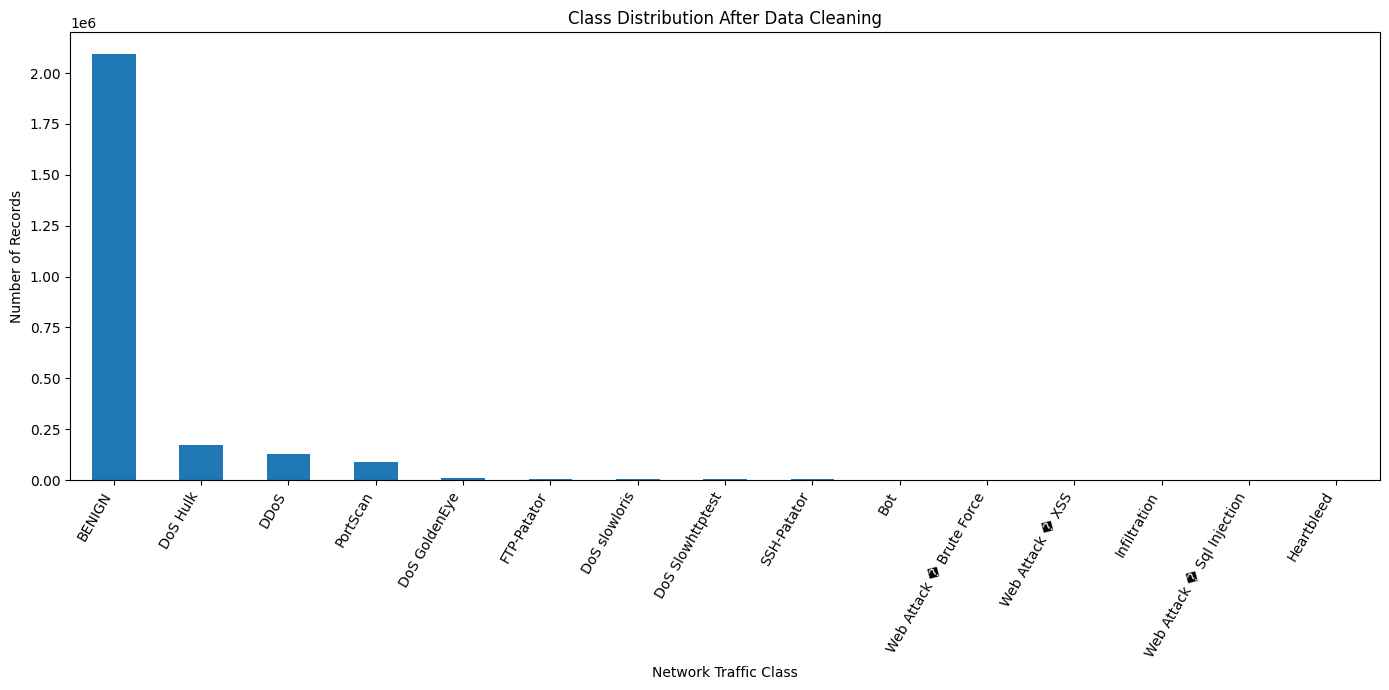


Number of classes after cleaning: 15


In [18]:
# STEP 5.10: CLASS DISTRIBUTION AFTER CLEANING

# 1. COUNT RECORDS IN EACH CLASS AFTER CLEANING
# WHAT: Counts the remaining records for every original label.
# WHY: We need to know how many examples are available for
# each attack before deciding how to handle class imbalance.
cleaned_class_counts = df['Label'].value_counts()

print("Class distribution after cleaning:")
print(cleaned_class_counts)

# 2. VISUALISE THE CLEANED CLASS DISTRIBUTION
# WHAT: Creates a bar chart of the remaining class counts.
# WHY: Helps us identify majority and minority classes
# after cleaning the dataset.
plt.figure(figsize=(14, 7))

cleaned_class_counts.plot(kind='bar')

plt.title('Class Distribution After Data Cleaning')
plt.xlabel('Network Traffic Class')
plt.ylabel('Number of Records')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

# 3. DISPLAY THE NUMBER OF CLASSES
# WHAT: Counts the distinct target labels.
# WHY: Confirms that the original attack categories remain.
print("\nNumber of classes after cleaning:", df['Label'].nunique())

- BENIGN dominates: It accounts for most of the dataset.
- Some attacks have reasonable representation: DoS Hulk, DDoS and PortScan have thousands of examples.
- Some attacks are extremely rare: Heartbleed has only 11 records, SQL Injection has 21, and Infiltration has 36.
If we train a model directly on this distribution, it may perform well on common classes but poorly on rare attacks.

In [19]:

# STEP 5.11: CLASS IMBALANCE PERCENTAGE ANALYSIS


# Count the records belonging to each original class.
# WHY: We need the class counts to calculate their proportions.
class_counts = df['Label'].value_counts()

# Calculate each class's percentage of the complete dataset.
# WHY: Percentages make it easier to compare class representation.
class_percentages = (class_counts / len(df)) * 100

# Combine the counts and percentages into a summary table.
# WHY: A table clearly shows which classes dominate the dataset.
class_summary = pd.DataFrame({
    'Record Count': class_counts,
    'Percentage (%)': class_percentages.round(4)
})

# Display the summary, sorted from most common to least common.
# WHY: This helps us prioritise the classes that need attention.
display(class_summary)

# Calculate the ratio between the largest and smallest classes.
# WHY: This gives a simple indication of how severe the imbalance is.
largest_class = class_counts.max()
smallest_class = class_counts.min()

imbalance_ratio = largest_class / smallest_class

print("\nLargest class:", class_counts.idxmax())
print("Smallest class:", class_counts.idxmin())
print(f"Majority-to-minority ratio: {imbalance_ratio:.2f}:1")

,Record Count,Percentage (%)
Label,,
BENIGN,2095057,83.1109
DoS Hulk,172846,6.8568
DDoS,128014,5.0783
PortScan,90694,3.5978
DoS GoldenEye,10286,0.4080
FTP-Patator,5931,0.2353
DoS slowloris,5385,0.2136
DoS Slowhttptest,5228,0.2074
SSH-Patator,3219,0.1277



Largest class: BENIGN
Smallest class: Heartbleed
Majority-to-minority ratio: 190459.73:1


We should use a hybrid class-imbalance strategy:
1. Reduce the BENIGN class using random undersampling.
2. Retain as many real attack records as possible, rather than immediately reducing every attack class to the same size.
3. Use class weights to give underrepresented classes more importance during training.
4. Investigate whether the rarest classes can be predicted reliably. Oversampling alone cannot create genuine new attack information.
5. Split the dataset before applying any resampling, and use a held-out test set to evaluate the final model.

In [20]:
# STEP 5.12: IDENTIFY EXTREMELY RARE CLASSES

# Count the records in each original attack class.
# WHY: We need the class sizes to identify categories with
# insufficient examples for reliable model training.
class_counts = df['Label'].value_counts()

# Select classes containing fewer than 100 records.
# WHY: Classes with very few examples are difficult to evaluate
# reliably and may not support a meaningful train/test split.
rare_classes = class_counts[class_counts < 100]

# Display the rare classes and their record counts.
# WHY: Helps us decide whether to retain, group, or separately
# investigate these classes.
print("Classes with fewer than 100 records:")
print(rare_classes)

# Display the number of rare classes.
# WHY: Summarises the scale of the rare-class problem.
print("\nNumber of extremely rare classes:", len(rare_classes))

Classes with fewer than 100 records:
Label
Infiltration                  36
Web Attack � Sql Injection    21
Heartbleed                    11
Name: count, dtype: int64

Number of extremely rare classes: 3


In [21]:
# ============================================================
# STEP 5.13: EXCLUDE EXTREMELY RARE CLASSES
# ============================================================

# 1. DEFINE THE CLASSES TO EXCLUDE
# WHAT: Lists the three classes with fewer than 50 records.
# WHY: Their very small sample sizes make reliable training
# and independent evaluation difficult.
rare_classes_to_remove = [
    'Infiltration',
    'Web Attack – Sql Injection',
    'Heartbleed'
]

# 2. CHECK THE EXACT LABEL SPELLING
# WHAT: Displays labels containing the words used above.
# WHY: Dataset labels must match exactly; otherwise, a class
# may not be removed as intended.
print("Original labels matching our selected classes:")
print(df['Label'][df['Label'].str.contains(
    'Infiltration|SQL Injection|Sql Injection|Heartbleed',
    case=False,
    na=False
)].value_counts())

# 3. REMOVE THE SELECTED CLASSES
# WHAT: Keeps all rows except those belonging to the excluded classes.
# WHY: This creates a dataset focused on the remaining classes.
# We preserve all available records from the retained classes.
labels_to_remove = df['Label'].str.contains(
    r'Infiltration|SQL Injection|Sql Injection|Heartbleed',
    case=False,
    na=False
)

df = df.loc[~labels_to_remove].copy()

# 4. VERIFY THE RESULT
# WHAT: Displays the remaining dataset size and class counts.
# WHY: Confirms the rare classes were excluded successfully.
print("\nDataset shape after excluding rare classes:", df.shape)

print("\nRemaining classes:")
print(df['Label'].value_counts())

print("\nNumber of remaining classes:", df['Label'].nunique())

Original labels matching our selected classes:
Label
Infiltration                  36
Web Attack � Sql Injection    21
Heartbleed                    11
Name: count, dtype: int64

Dataset shape after excluding rare classes: (2520730, 79)

Remaining classes:
Label
BENIGN                      2095057
DoS Hulk                     172846
DDoS                         128014
PortScan                      90694
DoS GoldenEye                 10286
FTP-Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1948
Web Attack � Brute Force       1470
Web Attack � XSS                652
Name: count, dtype: int64

Number of remaining classes: 12


In [24]:
# ============================================================
# STEP 5.14: MAJORITY CLASS UNDERSAMPLING
# ============================================================

# 1. SEPARATE BENIGN AND ATTACK RECORDS
# WHAT: Creates separate DataFrames for normal traffic and attacks.
# WHY: BENIGN is the majority class, so we want to reduce its size
# while preserving the available records from the attack classes.

benign_data = df[df['Label'] == 'BENIGN'].copy()
attack_data = df[df['Label'] != 'BENIGN'].copy()

# 2. DISPLAY THE ORIGINAL COUNTS
# WHAT: Counts normal and attack records before undersampling.
# WHY: Provides a baseline to compare the effect of undersampling.

print("BENIGN records before undersampling:", len(benign_data))
print("Attack records before undersampling:", len(attack_data))

# 3. RANDOMLY SELECT 100,000 BENIGN RECORDS
# WHAT: Samples 100,000 BENIGN records from the majority class.
# WHY: Reduces dataset size and training time without removing
# any of the available records from the attack classes.
# random_state=42 ensures the same sample can be reproduced.

benign_sample = benign_data.sample(
    n=100_000,
    random_state=42
)

# 4. COMBINE THE SELECTED BENIGN RECORDS WITH ALL ATTACK RECORDS
# WHAT: Creates a new dataset containing the sampled normal traffic
# and all available records from the 11 retained attack classes.
# WHY: Preserves attack examples while reducing the majority class.

balanced_df = pd.concat(
    [benign_sample, attack_data],
    ignore_index=True
)

# 5. SHUFFLE THE COMBINED DATASET
# WHAT: Randomly rearranges the row order.
# WHY: Prevents records from being grouped by class in the dataset.
# This does not replace a proper train/test split.

balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# 6. CHECK THE FINAL DATASET
# WHAT: Displays the dataset size and class distribution.
# WHY: Verifies that undersampling worked and all retained
# attack classes are still present.

print("\nDataset shape after undersampling:", balanced_df.shape)

print("\nClass distribution after undersampling:")
print(balanced_df['Label'].value_counts())

print("\nNumber of classes:", balanced_df['Label'].nunique())

BENIGN records before undersampling: 2095057
Attack records before undersampling: 425673

Dataset shape after undersampling: (525673, 79)

Class distribution after undersampling:
Label
DoS Hulk                    172846
DDoS                        128014
BENIGN                      100000
PortScan                     90694
DoS GoldenEye                10286
FTP-Patator                   5931
DoS slowloris                 5385
DoS Slowhttptest              5228
SSH-Patator                   3219
Bot                           1948
Web Attack � Brute Force      1470
Web Attack � XSS               652
Name: count, dtype: int64

Number of classes: 12


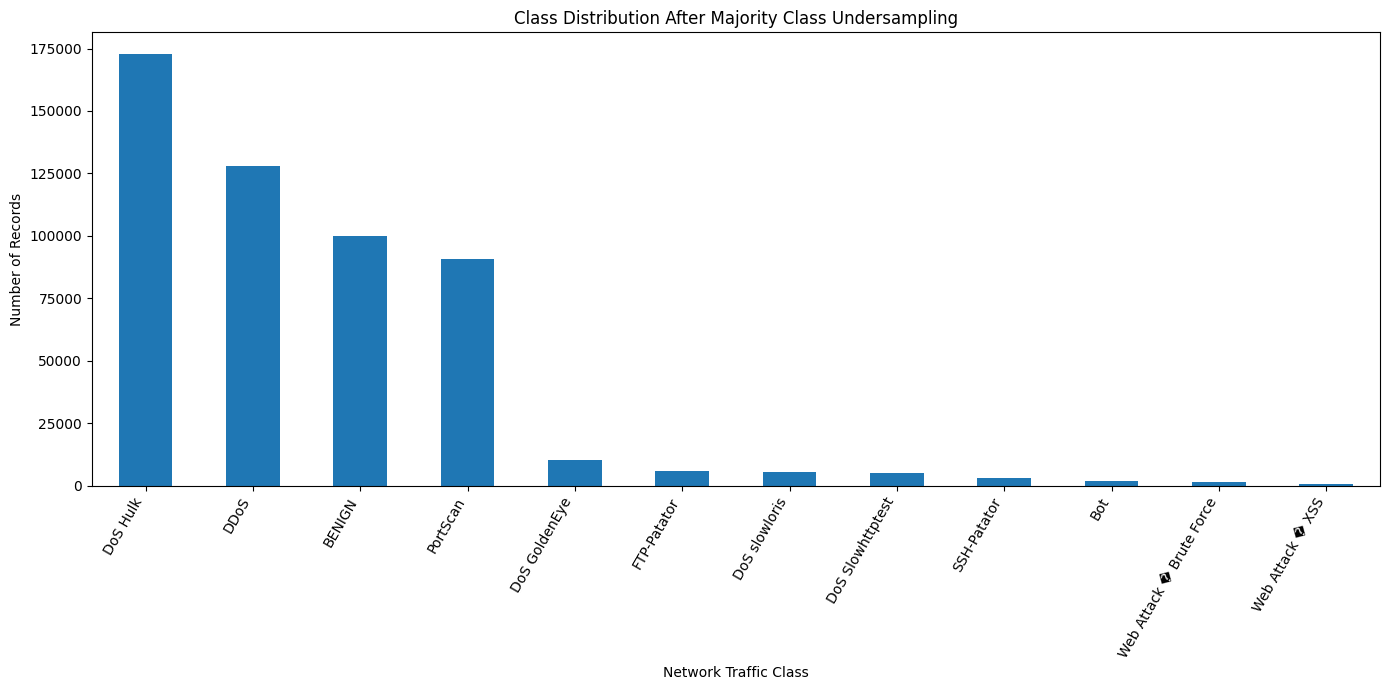

In [26]:
# STEP 5.15: CLASS DISTRIBUTION AFTER UNDERSAMPLING

# Count records in each class after undersampling.
# WHY: We need to verify the number of records retained per class.
class_counts = balanced_df['Label'].value_counts()

# Create a bar chart to compare the class sizes.
# WHY: Visualisation helps us identify any remaining imbalance.
plt.figure(figsize=(14, 7))
class_counts.plot(kind='bar')

# Add descriptive labels to the chart.
# WHY: Makes the chart easier to understand and present in interviews.
plt.title('Class Distribution After Majority Class Undersampling')
plt.xlabel('Network Traffic Class')
plt.ylabel('Number of Records')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()

# Display the chart.
plt.show()

In [27]:
# STEP 5.15: FINAL DATASET VERIFICATION


# 1. CHECK DATASET SIZE
# WHAT: Displays the number of rows and columns.
# WHY: Confirms the dataset size before further preprocessing.
print("Dataset shape:", balanced_df.shape)

# 2. CHECK THE NUMBER OF CLASSES
# WHAT: Counts the unique target labels.
# WHY: Confirms that multiclass classification is possible.
print("\nNumber of classes:", balanced_df['Label'].nunique())

# 3. CHECK THE CLASS DISTRIBUTION
# WHAT: Counts the records belonging to each class.
# WHY: Verifies that BENIGN contains 100,000 records and
# that all retained attack classes are present.
print("\nClass distribution:")
print(balanced_df['Label'].value_counts())

# 4. CHECK MISSING VALUES
# WHAT: Counts all missing cells.
# WHY: Confirms that the current dataset has no missing values.
print("\nMissing values:", balanced_df.isnull().sum().sum())

# 5. CHECK DUPLICATE RECORDS
# WHAT: Counts exact duplicate rows.
# WHY: Confirms that duplicate removal remains effective.
print("Duplicate rows:", balanced_df.duplicated().sum())

Dataset shape: (525673, 79)

Number of classes: 12

Class distribution:
Label
DoS Hulk                    172846
DDoS                        128014
BENIGN                      100000
PortScan                     90694
DoS GoldenEye                10286
FTP-Patator                   5931
DoS slowloris                 5385
DoS Slowhttptest              5228
SSH-Patator                   3219
Bot                           1948
Web Attack � Brute Force      1470
Web Attack � XSS               652
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0


In [28]:

# STEP 5.16: DATA TYPE VALIDATION

# 1. DISPLAY THE DATA TYPES OF ALL COLUMNS
# WHAT: Shows whether each column contains integers, decimals,
# text, or another data type.
# WHY: Most of our network traffic features should be numerical.
# We need to identify unexpected data types before modelling.
print("Data types of all columns:")
print(balanced_df.dtypes.value_counts())

# 2. IDENTIFY NON-NUMERICAL COLUMNS
# WHAT: Selects columns that are not numeric.
# WHY: Text features may require encoding or investigation
# before they can be used by a machine learning model.
non_numeric_columns = balanced_df.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNon-numerical columns:")
print(non_numeric_columns)

# 3. CHECK THE TARGET COLUMN SEPARATELY
# WHAT: Displays the data type of the Label column.
# WHY: Label is expected to contain the names of the classes,
# rather than numerical network traffic measurements.
print("\nTarget column data type:")
print(balanced_df['Label'].dtype)

Data types of all columns:
int64      54
float64    24
object      1
Name: count, dtype: int64

Non-numerical columns:
['Label']

Target column data type:
object


In [29]:
# STEP 5.17: NEGATIVE VALUE ANALYSIS

# 1. SELECT THE NUMERICAL INPUT FEATURES
# WHAT: Selects all numerical columns except the target label.
# WHY: Negative-value checks should apply to input features,
# not the text-based Label column.
X_numeric = balanced_df.drop(columns=['Label']).select_dtypes(
    include=np.number
)

# 2. COUNT NEGATIVE VALUES IN EACH FEATURE
# WHAT: Counts values smaller than zero in every numerical feature.
# WHY: Helps identify features that may contain unusual values.
negative_counts = (X_numeric < 0).sum()

# 3. DISPLAY ONLY FEATURES CONTAINING NEGATIVE VALUES
# WHAT: Filters the results to show features with negative values.
# WHY: Makes it easier to investigate potentially invalid values.
negative_features = negative_counts[negative_counts > 0]

print("Features containing negative values:")
print(negative_features)

# 4. DISPLAY THE TOTAL NUMBER OF NEGATIVE CELLS
# WHAT: Adds the negative-value counts across all features.
# WHY: Provides an overview of how widespread negative values are.
print("\nTotal negative feature values:", negative_counts.sum())

Features containing negative values:
Flow Duration                   4
Flow Bytes/s                    4
Flow Packets/s                  4
Flow IAT Mean                   4
Flow IAT Max                    4
Flow IAT Min                  323
Fwd IAT Min                    17
Fwd Header Length               2
Bwd Header Length               1
Fwd Header Length.1             2
Init_Win_bytes_forward      43592
Init_Win_bytes_backward    118316
min_seg_size_forward            2
dtype: int64

Total negative feature values: 162275


In [30]:
# STEP 5.18: INVESTIGATE NEGATIVE FEATURE VALUES

# 1. SELECT FEATURES THAT CONTAIN NEGATIVE VALUES
# WHAT: Identifies the numerical features with negative values.
# WHY: We need to inspect their actual values before deciding
# whether they are valid measurements or data-quality issues.
negative_feature_names = negative_features.index.tolist()

# 2. DISPLAY THE MINIMUM VALUE OF EACH AFFECTED FEATURE
# WHAT: Finds the smallest value in each selected feature.
# WHY: Helps us identify suspicious values such as -1 or
# unusually large negative numbers.
print("Minimum values in features containing negatives:")

print(
    balanced_df[negative_feature_names]
    .min()
    .sort_values()
)

# 3. DISPLAY SAMPLE ROWS CONTAINING NEGATIVE VALUES
# WHAT: Shows up to five records containing at least one negative
# numerical feature value.
# WHY: Lets us inspect the affected records without displaying
# the entire dataset.
negative_rows = balanced_df[
    (balanced_df[negative_feature_names] < 0).any(axis=1)
]

print("\nNumber of rows containing negative values:", len(negative_rows))

display(negative_rows.head())

Minimum values in features containing negatives:
Fwd Header Length         -3.221223e+10
Fwd Header Length.1       -3.221223e+10
min_seg_size_forward      -5.368707e+08
Bwd Header Length         -8.388514e+07
Flow Bytes/s              -1.200000e+07
Flow Packets/s            -2.000000e+06
Flow IAT Min              -1.300000e+01
Fwd IAT Min               -1.200000e+01
Flow IAT Max              -1.000000e+00
Flow IAT Mean             -1.000000e+00
Flow Duration             -1.000000e+00
Init_Win_bytes_forward    -1.000000e+00
Init_Win_bytes_backward   -1.000000e+00
dtype: float64

Number of rows containing negative values: 118638


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,5070309,5,0,30,0,6,6,6.0,0.0,0,0,0.0,0.0,5.916799,0.986133,1267577.250,2.534192e+06,5068865,4,5070309,1267577.250,2.534192e+06,5068865,4,0,0.0,0.0,0,0,0,0,0,0,100,0,0.986133,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,7.2,6.0,0.0,100,0,0,0,0,0,0,5,30,0,0,256,-1,4,20,1444.0,0.0,1444,1444,5068865.0,0.0,5068865,5068865,DDoS
18,80,3003087,3,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,0.000000,0.998972,1501543.500,7.105568e+05,2003983,999104,3003087,1501543.500,7.105568e+05,2003983,999104,0,0.0,0.0,0,0,0,0,0,0,120,0,0.998972,0.000000,0,0,0.000000,0.000000,0.000000,0,0,0,1,0,0,0,0,0,0.0,0.0,0.0,120,0,0,0,0,0,0,3,0,0,0,29200,-1,0,40,0.0,0.0,0,0,0.0,0.0,0,0,DoS slowloris
28,80,10903734,4,0,24,0,6,6,6.0,0.0,0,0,0.0,0.0,2.201081,0.366847,3634578.000,6.291812e+06,10900000,999,10900000,3634578.000,6.291812e+06,10900000,999,0,0.0,0.0,0,0,0,0,0,0,80,0,0.366847,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,7.5,6.0,0.0,80,0,0,0,0,0,0,4,24,0,0,256,-1,3,20,3997.0,0.0,3997,3997,10900000.0,0.0,10900000,10900000,DDoS
30,80,8099821,4,0,24,0,6,6,6.0,0.0,0,0,0.0,0.0,2.963028,0.493838,2699940.333,4.675551e+06,8098801,3,8099821,2699940.333,4.675551e+06,8098801,3,0,0.0,0.0,0,0,0,0,0,0,80,0,0.493838,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,7.5,6.0,0.0,80,0,0,0,0,0,0,4,24,0,0,256,-1,3,20,1020.0,0.0,1020,1020,8098801.0,0.0,8098801,8098801,DDoS
33,53,23811,1,1,48,80,48,48,48.0,0.0,80,80,80.0,0.0,5375.666709,83.994792,23811.000,0.000000e+00,23811,23811,0,0.000,0.000000e+00,0,0,0,0.0,0.0,0,0,0,0,0,0,32,32,41.997396,41.997396,48,80,58.666667,18.475209,341.333333,0,0,0,0,0,0,0,0,1,88.0,48.0,80.0,32,0,0,0,0,0,0,1,48,1,80,-1,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [33]:
# STEP 5.19: INVESTIGATE SUSPICIOUS NEGATIVE VALUES

# Select numerical input features, excluding the target label.
# WHY: We want to inspect network measurements, not class names.
X_numeric = balanced_df.drop(columns=['Label']).select_dtypes(
    include=np.number
)

# Identify features containing negative values.
# WHY: This helps us focus on features that need investigation.
negative_features = X_numeric.columns[(X_numeric < 0).any()].tolist()

# Display the minimum value of each affected feature.
# WHY: Extremely large negative values may indicate data-quality
# issues, while values such as -1 may be sentinel values.
print("Minimum values in features containing negatives:")
print(X_numeric[negative_features].min().sort_values())

# Count values below -1 in each affected feature.
# WHY: Helps identify values that deserve closer investigation.
print("\nNumber of values below -1 in each feature:")
print((X_numeric[negative_features] < -1).sum().sort_values(ascending=False))

# Display a small sample of rows containing negative values.
# WHY: Allows us to inspect examples without displaying the
# entire dataset.
negative_rows = balanced_df[
    (X_numeric < 0).any(axis=1)
]

print("\nRows containing negative values:", len(negative_rows))
display(negative_rows.head())

Minimum values in features containing negatives:
Fwd Header Length         -3.221223e+10
Fwd Header Length.1       -3.221223e+10
min_seg_size_forward      -5.368707e+08
Bwd Header Length         -8.388514e+07
Flow Bytes/s              -1.200000e+07
Flow Packets/s            -2.000000e+06
Flow IAT Min              -1.300000e+01
Fwd IAT Min               -1.200000e+01
Flow IAT Max              -1.000000e+00
Flow IAT Mean             -1.000000e+00
Flow Duration             -1.000000e+00
Init_Win_bytes_forward    -1.000000e+00
Init_Win_bytes_backward   -1.000000e+00
dtype: float64

Number of values below -1 in each feature:
Flow IAT Min               23
Flow Packets/s              4
Flow Bytes/s                4
Fwd IAT Min                 2
Fwd Header Length           2
min_seg_size_forward        2
Fwd Header Length.1         2
Bwd Header Length           1
Flow Duration               0
Flow IAT Max                0
Flow IAT Mean               0
Init_Win_bytes_forward      0
Init_Win_byt

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,5070309,5,0,30,0,6,6,6.0,0.0,0,0,0.0,0.0,5.916799,0.986133,1267577.250,2.534192e+06,5068865,4,5070309,1267577.250,2.534192e+06,5068865,4,0,0.0,0.0,0,0,0,0,0,0,100,0,0.986133,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,7.2,6.0,0.0,100,0,0,0,0,0,0,5,30,0,0,256,-1,4,20,1444.0,0.0,1444,1444,5068865.0,0.0,5068865,5068865,DDoS
18,80,3003087,3,0,0,0,0,0,0.0,0.0,0,0,0.0,0.0,0.000000,0.998972,1501543.500,7.105568e+05,2003983,999104,3003087,1501543.500,7.105568e+05,2003983,999104,0,0.0,0.0,0,0,0,0,0,0,120,0,0.998972,0.000000,0,0,0.000000,0.000000,0.000000,0,0,0,1,0,0,0,0,0,0.0,0.0,0.0,120,0,0,0,0,0,0,3,0,0,0,29200,-1,0,40,0.0,0.0,0,0,0.0,0.0,0,0,DoS slowloris
28,80,10903734,4,0,24,0,6,6,6.0,0.0,0,0,0.0,0.0,2.201081,0.366847,3634578.000,6.291812e+06,10900000,999,10900000,3634578.000,6.291812e+06,10900000,999,0,0.0,0.0,0,0,0,0,0,0,80,0,0.366847,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,7.5,6.0,0.0,80,0,0,0,0,0,0,4,24,0,0,256,-1,3,20,3997.0,0.0,3997,3997,10900000.0,0.0,10900000,10900000,DDoS
30,80,8099821,4,0,24,0,6,6,6.0,0.0,0,0,0.0,0.0,2.963028,0.493838,2699940.333,4.675551e+06,8098801,3,8099821,2699940.333,4.675551e+06,8098801,3,0,0.0,0.0,0,0,0,0,0,0,80,0,0.493838,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,7.5,6.0,0.0,80,0,0,0,0,0,0,4,24,0,0,256,-1,3,20,1020.0,0.0,1020,1020,8098801.0,0.0,8098801,8098801,DDoS
33,53,23811,1,1,48,80,48,48,48.0,0.0,80,80,80.0,0.0,5375.666709,83.994792,23811.000,0.000000e+00,23811,23811,0,0.000,0.000000e+00,0,0,0,0.0,0.0,0,0,0,0,0,0,32,32,41.997396,41.997396,48,80,58.666667,18.475209,341.333333,0,0,0,0,0,0,0,0,1,88.0,48.0,80.0,32,0,0,0,0,0,0,1,48,1,80,-1,-1,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


Step 5.19 — Results
- Rows containing negative values: 118,638
- Flow Duration, Flow IAT Max, and Flow IAT Mean have minimum values of -1.
- Init_Win_bytes_forward and Init_Win_bytes_backward also have minimum values of -1.
- Some features contain extremely large negative values, including Fwd Header Length and min_seg_size_forward.
Important: We should not delete all 118,638 rows. Some negative values may be sentinel values, while the extreme values need investigation

In [34]:
# STEP 5.20: INSPECT EXTREME NEGATIVE VALUES

# List features that contain suspicious negative values.
# WHY: These features had unusually large negative minimum values.
suspicious_features = [
    'Fwd Header Length',
    'Fwd Header Length.1',
    'min_seg_size_forward',
    'Bwd Header Length',
    'Flow Bytes/s',
    'Flow Packets/s',
    'Flow IAT Min',
    'Fwd IAT Min'
]

# Keep only columns that exist in our dataset.
# WHY: Prevents errors if a feature name is absent.
suspicious_features = [
    col for col in suspicious_features
    if col in balanced_df.columns
]

# Show records containing values below -1 in these features.
# WHY: Lets us inspect the actual records before deciding
# whether they should be corrected or excluded.
for col in suspicious_features:
    extreme_rows = balanced_df[balanced_df[col] < -1]

    print(f"\nFeature: {col}")
    print("Values below -1:", len(extreme_rows))

    if len(extreme_rows) > 0:
        display(extreme_rows[['Label', col]].head(5))


Feature: Fwd Header Length
Values below -1: 2


,Label,Fwd Header Length
4311,BENIGN,-167770458
411600,BENIGN,-32212234632



Feature: Fwd Header Length.1
Values below -1: 2


,Label,Fwd Header Length.1
4311,BENIGN,-167770458
411600,BENIGN,-32212234632



Feature: min_seg_size_forward
Values below -1: 2


...

,Label,Flow Packets/s
8823,BENIGN,-2000000.0
337195,BENIGN,-2000000.0
399848,BENIGN,-2000000.0
408406,BENIGN,-2000000.0



Feature: Flow IAT Min
Values below -1: 23


,Label,Flow IAT Min
31629,DoS Hulk,-2
37883,DoS Hulk,-3
85084,DoS Hulk,-3
129681,DoS Hulk,-13
146698,BENIGN,-2



Feature: Fwd IAT Min
Values below -1: 2


,Label,Fwd IAT Min
210199,DDoS,-12
446562,DoS Hulk,-8


In [35]:

# STEP 5.21: DUPLICATE FEATURE INVESTIGATION

# WHAT: Compare the two forward-header-length columns.
# WHY: Their names suggest that one may be a duplicate created
# when combining CSV files. We must verify before removing either.

if (
    'Fwd Header Length' in balanced_df.columns
    and 'Fwd Header Length.1' in balanced_df.columns
):

    # Check whether both columns contain exactly the same values.
    identical = balanced_df['Fwd Header Length'].equals(
        balanced_df['Fwd Header Length.1']
    )

    print("Are the two columns identical?", identical)

    # Show a few values side by side for inspection.
    print("\nSample values:")
    display(
        balanced_df[
            ['Fwd Header Length', 'Fwd Header Length.1']
        ].head(10)
    )

else:
    print("One or both columns were not found.")

Are the two columns identical? True

Sample values:


,Fwd Header Length,Fwd Header Length.1
0,100,100
1,24,24
2,72,72
3,72,72
4,24,24
5,40,40
6,220,220
7,64,64
8,104,104
9,232,232


In [36]:
# STEP 5.22: REMOVE THE DUPLICATE FEATURE

# WHAT: Removes Fwd Header Length.1 from the dataset.
# WHY: We confirmed that it is identical to Fwd Header Length.
# This removes redundancy without losing unique information.

balanced_df.drop(
    columns=['Fwd Header Length.1'],
    inplace=True
)

# Verify the updated dataset.
# WHY: Confirms that the feature was removed successfully.
print("Dataset shape after removing duplicate feature:",
      balanced_df.shape)

print("\nIs the duplicate column still present?",
      'Fwd Header Length.1' in balanced_df.columns)

Dataset shape after removing duplicate feature: (525673, 78)

Is the duplicate column still present? False


In [37]:
# STEP 5.23: VALIDATE SUSPICIOUS FEATURE VALUES

# Select features that we previously identified as suspicious.
# WHY: We want to inspect their current values without repeating
# the complete negative-value analysis.
features_to_check = [
    'Flow Duration',
    'Flow Bytes/s',
    'Flow Packets/s',
    'Fwd Header Length',
    'Bwd Header Length',
    'min_seg_size_forward',
    'Init_Win_bytes_forward',
    'Init_Win_bytes_backward'
]

# Keep only columns that exist in the current dataset.
# WHY: Prevents errors if a feature name is absent.
features_to_check = [
    col for col in features_to_check
    if col in balanced_df.columns
]

# Display minimum, median, and maximum values for each feature.
# WHY: Helps us distinguish ordinary values from extreme values.
display(
    balanced_df[features_to_check]
    .describe()
    .loc[['min', '50%', 'max']]
    .T
)

# Count values below -1 in the selected features.
# WHY: Highlights extreme negative values that need further review.
print("\nNumber of values below -1:")
print(
    (balanced_df[features_to_check] < -1)
    .sum()
    .sort_values(ascending=False)
)

,min,50%,max
Flow Duration,-1.000000e+00,1.803099e+06,1.200000e+08
Flow Bytes/s,-1.200000e+07,1.796272e+02,2.071000e+09
Flow Packets/s,-2.000000e+06,4.416602e+00,3.000000e+06
Fwd Header Length,-3.221223e+10,9.600000e+01,4.167632e+06
Bwd Header Length,-8.388514e+07,9.200000e+01,5.392380e+06
min_seg_size_forward,-5.368707e+08,2.000000e+01,6.000000e+01
Init_Win_bytes_forward,-1.000000e+00,2.740000e+02,6.553500e+04
Init_Win_bytes_backward,-1.000000e+00,2.290000e+02,6.553500e+04



Number of values below -1:
Flow Bytes/s               4
Flow Packets/s             4
Fwd Header Length          2
min_seg_size_forward       2
Bwd Header Length          1
Flow Duration              0
Init_Win_bytes_forward     0
Init_Win_bytes_backward    0
dtype: int64


What does this mean?
- Flow Duration: The value −1 needs investigation because duration should not be negative.
- Flow Bytes/s and Flow Packets/s: The extreme negative values are suspicious.
- Header-length features: The extreme negative values are likely invalid and should be verified.
- Initial window-size features: The value −1 may be a sentinel value, so we shouldn't automatically replace it.

In [38]:
# STEP 5.24: INSPECT EXTREME NEGATIVE RECORDS

# WHAT: Selects features containing suspicious negative values.
# WHY: We want to examine the exact records before deciding
# whether to correct or exclude any measurements.

suspicious_features = [
    'Flow Bytes/s',
    'Flow Packets/s',
    'Fwd Header Length',
    'Bwd Header Length',
    'min_seg_size_forward'
]

# WHAT: Keep only columns available in the current dataset.
# WHY: Prevents errors if a column name differs.
suspicious_features = [
    col for col in suspicious_features
    if col in balanced_df.columns
]

# WHAT: Select records with values below -1 in these features.
# WHY: These are the extreme negative values that need review.
extreme_mask = (
    balanced_df[suspicious_features] < -1
).any(axis=1)

# WHAT: Display the label and suspicious feature values.
# WHY: Helps us see which attack classes are affected and
# how extreme the values are.
columns_to_display = ['Label'] + suspicious_features

print("Number of records with extreme negative values:",
      extreme_mask.sum())

display(balanced_df.loc[extreme_mask, columns_to_display])

Number of records with extreme negative values: 6


,Label,Flow Bytes/s,Flow Packets/s,Fwd Header Length,Bwd Header Length,min_seg_size_forward
4311,BENIGN,1.014217e+01,2.112953e-01,-167770458,-83885145,-83885313
8823,BENIGN,-1.200000e+07,-2.000000e+06,20,20,20
337195,BENIGN,-8.000000e+06,-2.000000e+06,20,24,20
399848,BENIGN,-1.200000e+07,-2.000000e+06,20,20,20
408406,BENIGN,-6.000000e+06,-2.000000e+06,20,40,20
411600,BENIGN,5.797360e+03,8.634365e+01,-32212234632,0,-536870660


In [42]:
# STEP 5.28: REMOVE RECORDS WITH EXTREME INVALID VALUES

# Count records before removal.
print("Rows before removal:", len(balanced_df))

# Remove the six records identified during inspection.
# WHY: Their extreme negative values appear invalid.
balanced_df = balanced_df.loc[~extreme_mask].copy()

# Reset the row index after removal.
balanced_df.reset_index(drop=True, inplace=True)

# Verify the dataset after removal.
print("Rows after removal:", len(balanced_df))
print("Remaining extreme records:",
      (balanced_df[suspicious_features] < -1).any(axis=1).sum())

Rows before removal: 525673
Rows after removal: 525667
Remaining extreme records: 0


In [43]:
# STEP 5.29: VERIFY DATASET QUALITY AFTER CLEANING

# Check the total number of missing values.
print("Missing values:", balanced_df.isnull().sum().sum())

# Check the total number of duplicate records.
print("Duplicate records:", balanced_df.duplicated().sum())

# Check the current dataset dimensions.
print("Dataset shape:", balanced_df.shape)

# Check the number of target classes.
print("Number of classes:", balanced_df['Label'].nunique())

# Display the number of records in each class.
print("\nClass distribution:")
print(balanced_df['Label'].value_counts())

Missing values: 0
Duplicate records: 0
Dataset shape: (525667, 78)
Number of classes: 12

Class distribution:
Label
DoS Hulk                    172846
DDoS                        128014
BENIGN                       99994
PortScan                     90694
DoS GoldenEye                10286
FTP-Patator                   5931
DoS slowloris                 5385
DoS Slowhttptest              5228
SSH-Patator                   3219
Bot                           1948
Web Attack � Brute Force      1470
Web Attack � XSS               652
Name: count, dtype: int64


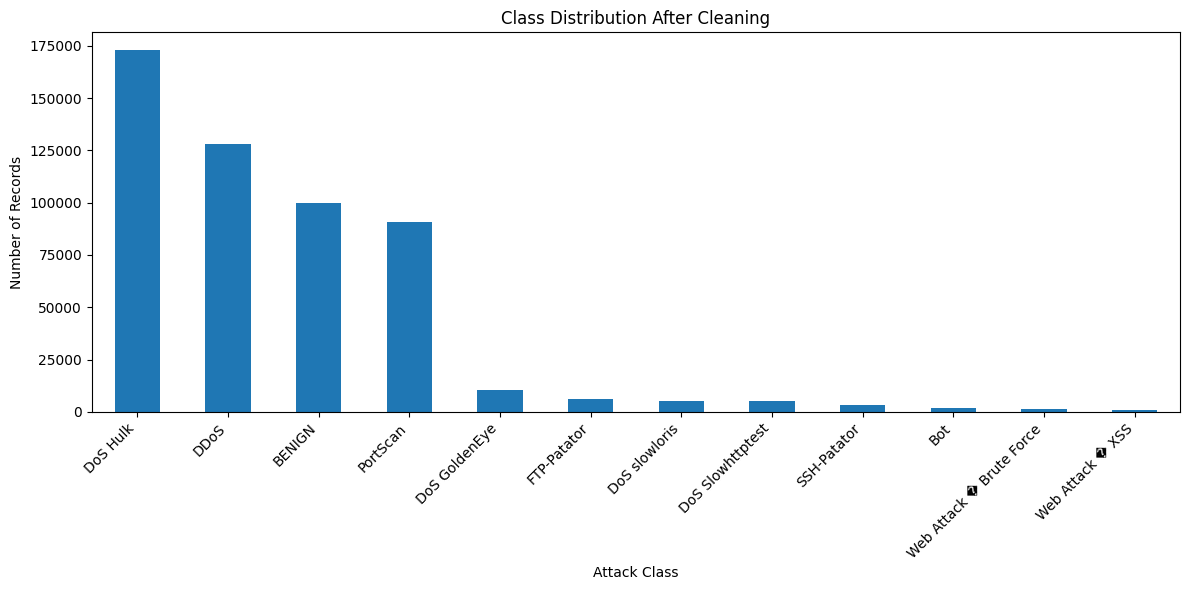

In [44]:
# STEP 5.30: VISUALIZE CLASS DISTRIBUTION

import matplotlib.pyplot as plt

# Count the records in each class.
class_counts = balanced_df['Label'].value_counts()

# Plot the class distribution.
plt.figure(figsize=(12, 6))
class_counts.plot(kind='bar')

plt.title('Class Distribution After Cleaning')
plt.xlabel('Attack Class')
plt.ylabel('Number of Records')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [45]:
# STEP 5.31: CLEAN TARGET LABEL TEXT

# Remove unnecessary spaces from the class labels.
balanced_df['Label'] = balanced_df['Label'].str.strip()

# Display the class names and counts.
print("Number of classes:", balanced_df['Label'].nunique())
print("\nClass distribution:")
print(balanced_df['Label'].value_counts())

Number of classes: 12

Class distribution:
Label
DoS Hulk                    172846
DDoS                        128014
BENIGN                       99994
PortScan                     90694
DoS GoldenEye                10286
FTP-Patator                   5931
DoS slowloris                 5385
DoS Slowhttptest              5228
SSH-Patator                   3219
Bot                           1948
Web Attack � Brute Force      1470
Web Attack � XSS               652
Name: count, dtype: int64


In [47]:
# ============================================================
# STEP 5.33: VERIFY NEGATIVE VALUES AFTER CLEANING
# ============================================================

# Select numerical features, excluding the target label.
features = balanced_df.drop(columns=['Label'])

# Count negative values in each feature.
negative_counts = (features < 0).sum()

# Display features containing negative values.
print("Features containing negative values:")
print(negative_counts[negative_counts > 0])

# Count all negative values across the dataset.
print("\nTotal negative values:", negative_counts.sum())

Features containing negative values:
Flow IAT Min                  319
Fwd IAT Min                    17
Init_Win_bytes_forward      43590
Init_Win_bytes_backward    118314
dtype: int64

Total negative values: 162240


In [48]:
# STEP 5.34: INSPECT REMAINING NEGATIVE VALUES

# Features that still contain negative values.
features_to_check = [
    'Flow IAT Min',
    'Fwd IAT Min',
    'Init_Win_bytes_forward',
    'Init_Win_bytes_backward'
]

# Display the number of negative values in each feature.
print("Negative value counts:")
print((balanced_df[features_to_check] < 0).sum())

# Display the unique negative values in each feature.
for feature in features_to_check:
    print(f"\nNegative values in {feature}:")
    print(sorted(balanced_df.loc[balanced_df[feature] < 0, feature].unique())[:20])

Negative value counts:
Flow IAT Min                  319
Fwd IAT Min                    17
Init_Win_bytes_forward      43590
Init_Win_bytes_backward    118314
dtype: int64

Negative values in Flow IAT Min:
[np.int64(-13), np.int64(-12), np.int64(-11), np.int64(-8), np.int64(-5), np.int64(-4), np.int64(-3), np.int64(-2), np.int64(-1)]

Negative values in Fwd IAT Min:
[np.int64(-12), np.int64(-8), np.int64(-1)]

Negative values in Init_Win_bytes_forward:
[np.int64(-1)]

Negative values in Init_Win_bytes_backward:
[np.int64(-1)]


In [49]:
# STEP 5.35: INSPECT NEGATIVE INTER-ARRIVAL TIME RECORDS

# Select records with negative inter-arrival times.
negative_iat = balanced_df[
    (balanced_df['Flow IAT Min'] < 0) |
    (balanced_df['Fwd IAT Min'] < 0)
]

# Display the affected records and their labels.
print("Records with negative inter-arrival times:",
      len(negative_iat))

display(
    negative_iat[
        ['Label', 'Flow IAT Min', 'Fwd IAT Min']
    ].head(20)
)

Records with negative inter-arrival times: 319


,Label,Flow IAT Min,Fwd IAT Min
6194,BENIGN,-1,183
7015,BENIGN,-1,1
7662,DoS Hulk,-1,0
8847,DoS Hulk,-1,5
9330,BENIGN,-1,49
9645,DoS Hulk,-1,995
15306,BENIGN,-1,3
20653,DDoS,-1,6
21882,DoS Hulk,-1,2
22338,BENIGN,-1,236


In [50]:
# STEP 5.36: COUNT NEGATIVE VALUES IN IAT FEATURES

# Count each negative value in Flow IAT Min.
print("Negative values in Flow IAT Min:")
print(
    balanced_df.loc[
        balanced_df['Flow IAT Min'] < 0,
        'Flow IAT Min'
    ].value_counts().sort_index()
)

# Count each negative value in Fwd IAT Min.
print("\nNegative values in Fwd IAT Min:")
print(
    balanced_df.loc[
        balanced_df['Fwd IAT Min'] < 0,
        'Fwd IAT Min'
    ].value_counts().sort_index()
)

Negative values in Flow IAT Min:
Flow IAT Min
-13      2
-12      5
-11      3
-8       1
-5       2
-4       1
-3       5
-2       4
-1     296
Name: count, dtype: int64

Negative values in Fwd IAT Min:
Fwd IAT Min
-12     1
-8      1
-1     15
Name: count, dtype: int64


IAT means Inter-Arrival Time—the time between network packets. These values should generally not be negative. However, we should investigate whether these are data errors before removing them.

In [51]:
# STEP 5.37: VERIFY NEGATIVE IAT VALUES IN ORIGINAL DATA

print("Original dataset - Flow IAT Min:")
print(df.loc[df['Flow IAT Min'] < 0, 'Flow IAT Min'].value_counts())

print("\nOriginal dataset - Fwd IAT Min:")
print(df.loc[df['Fwd IAT Min'] < 0, 'Fwd IAT Min'].value_counts())

Original dataset - Flow IAT Min:
Flow IAT Min
-1     2738
-12      32
-2       27
-3       17
-4       17
-11      12
-13      12
-5       11
-10       4
-14       2
-6        2
-8        1
Name: count, dtype: int64

Original dataset - Fwd IAT Min:
Fwd IAT Min
-1     15
-8      1
-12     1
Name: count, dtype: int64


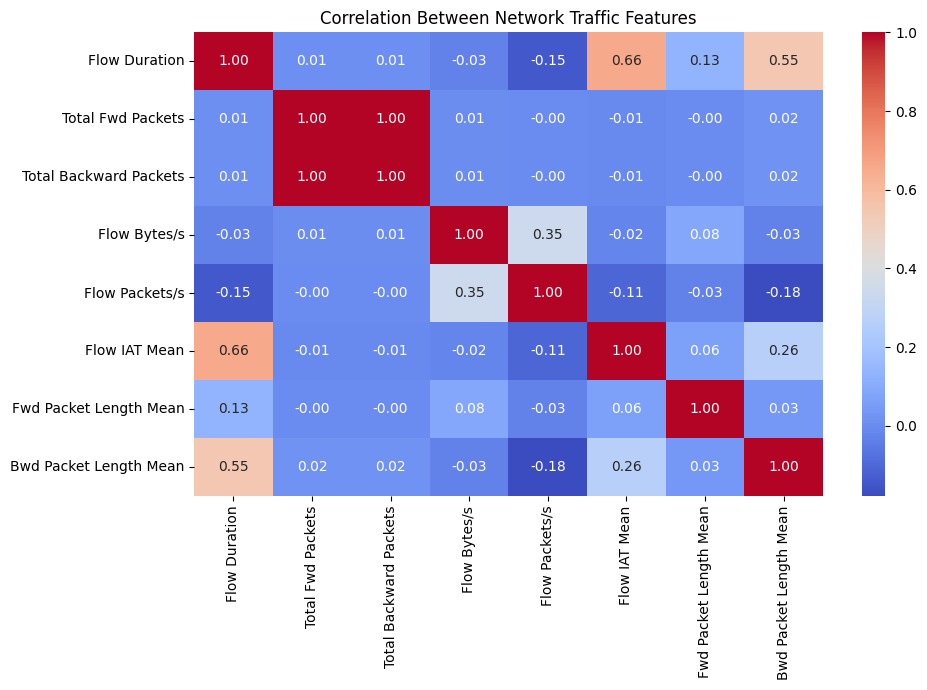

In [53]:
# STEP 6.1: CORRELATION HEATMAP

# Import the required libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Select important numerical network traffic features.
selected_features = [
    'Flow Duration',
    'Total Fwd Packets',
    'Total Backward Packets',
    'Flow Bytes/s',
    'Flow Packets/s',
    'Flow IAT Mean',
    'Fwd Packet Length Mean',
    'Bwd Packet Length Mean'
]

# Select 10,000 records to make the calculation faster.
sample_df = balanced_df.sample(
    n=min(10000, len(balanced_df)),
    random_state=42
)

# Calculate the correlation between the selected features.
correlation = sample_df[selected_features].corr()

# Plot the correlation heatmap.
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

# Add the chart title.
plt.title('Correlation Between Network Traffic Features')

# Display the heatmap.
plt.tight_layout()
plt.show()


. What does this graph show?
A correlation heatmap shows how strongly two numerical features are related to each other.

The values range from -1 to +1:
Correlation value	Meaning
+1.00	Perfect positive relationship
Close to +1	Strong positive relationship
Close to 0	Little or no linear relationship
Close to -1	Strong negative relationship


- 🔴 Red indicates a strong positive correlation.
- 🔵 Blue indicates a negative correlation.
- Lighter colours indicate weaker relationships.
The diagonal is always 1.00 because each feature is perfectly correlated with itself.
2. Interpretation of your output
A. Total Fwd Packets and Total Backward Packets = 1.00
These two features have an extremely strong positive correlation in your sample.

This means they tend to increase together. However, a correlation of 1.00 does not necessarily mean the two features are identical.

What we should do: Keep both for now. We can investigate them further before deciding whether to remove a feature.
B. Flow Duration and Flow IAT Mean = 0.66
This shows a moderately strong positive relationship.

Longer network flows tend to be associated with higher average inter-arrival times in this sample.
C. Flow Duration and Bwd Packet Length Mean = 0.55
This indicates a moderate positive relationship between flow duration and average backward packet length.
D. Flow Bytes/s and Flow Packets/s = 0.35
These features have a moderate positive relationship. Network flows with higher byte rates may also have higher packet rates.
E. Flow Packets/s and Bwd Packet Length Mean = -0.18
This indicates a weak negative relationship. In this sample, higher packet rates tend to be associated with slightly lower average backward packet lengths.
F. Most other relationships are close to zero
For example:
- Flow Duration and Total Fwd Packets = 0.01
- Flow Bytes/s and Fwd Packet Length Mean = 0.08

In [54]:

# STEP 6.2: IDENTIFY HIGHLY CORRELATED FEATURES

# Calculate correlations between the selected features.
correlation_matrix = sample_df[selected_features].corr().abs()

# Keep only the upper triangle to avoid duplicate pairs.
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation above 0.95.
high_correlation_pairs = (
    upper_triangle.stack()
    .loc[lambda values: values > 0.95]
    .sort_values(ascending=False)
)

# Display the highly correlated feature pairs.
print("Highly correlated feature pairs (correlation > 0.95):")

if high_correlation_pairs.empty:
    print("No highly correlated pairs found.")
else:
    print(high_correlation_pairs)


Highly correlated feature pairs (correlation > 0.95):
Total Fwd Packets  Total Backward Packets    0.999998
dtype: float64


In [55]:
# STEP 6.3: CHECK HIGH CORRELATION ACROSS ALL FEATURES

# Select all numerical input features, excluding the target label.
numerical_features = balanced_df.select_dtypes(
    include=np.number
).columns.tolist()

# Calculate correlations using a sample to reduce computation time.
correlation_sample = balanced_df.sample(
    n=min(20000, len(balanced_df)),
    random_state=42
)

correlation_matrix = correlation_sample[numerical_features].corr().abs()

# Keep only the upper triangle to avoid duplicate pairs.
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation above 0.95.
high_corr_pairs = (
    upper_triangle.stack()
    .loc[lambda values: values > 0.95]
    .sort_values(ascending=False)
)

print("Number of highly correlated feature pairs:", len(high_corr_pairs))
print("\nHighly correlated feature pairs:")
print(high_corr_pairs)

Number of highly correlated feature pairs: 106

Highly correlated feature pairs:
Total Fwd Packets            Subflow Fwd Packets      1.000000
Total Backward Packets       Subflow Bwd Packets      1.000000
Total Length of Fwd Packets  Subflow Fwd Bytes        1.000000
Fwd Packet Length Mean       Avg Fwd Segment Size     1.000000
Fwd PSH Flags                SYN Flag Count           1.000000
                                                        ...   
Idle Max                     Idle Min                 0.953766
Flow IAT Max                 Idle Min                 0.951896
Fwd IAT Max                  Idle Min                 0.951854
Bwd Packet Length Mean       Bwd Packet Length Std    0.950131
Bwd Packet Length Std        Avg Bwd Segment Size     0.950131
Length: 106, dtype: float64


In [56]:

# STEP 5.39: FINAL DATA QUALITY CHECK

# Check the total number of missing values.
print("Total missing values:", balanced_df.isnull().sum().sum())

# Check the total number of duplicate rows.
print("Duplicate rows:", balanced_df.duplicated().sum())

# Display the dataset dimensions.
print("Dataset shape:", balanced_df.shape)

# Check the number of target classes.
print("Number of classes:", balanced_df['Label'].nunique())

# Display the number of records in each class.
print("\nClass distribution:")
print(balanced_df['Label'].value_counts())


Total missing values: 0
Duplicate rows: 0
Dataset shape: (525667, 78)
Number of classes: 12

Class distribution:
Label
DoS Hulk                    172846
DDoS                        128014
BENIGN                       99994
PortScan                     90694
DoS GoldenEye                10286
FTP-Patator                   5931
DoS slowloris                 5385
DoS Slowhttptest              5228
SSH-Patator                   3219
Bot                           1948
Web Attack � Brute Force      1470
Web Attack � XSS               652
Name: count, dtype: int64


In [60]:

# STEP 6: ENCODE TARGET LABELS

from sklearn.preprocessing import LabelEncoder

# Separate input features and target labels.
X = balanced_df.drop(columns=['Label'])
y = balanced_df['Label']

# Convert text labels into numeric labels.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Display the mapping between attack names and encoded values.
print("Target label mapping:")
for number, label in enumerate(label_encoder.classes_):
    print(f"{label} = {number}")

# Display dataset dimensions.
print("\nInput features shape:", X.shape)
print("Encoded target shape:", y_encoded.shape)
print("Number of classes:", len(label_encoder.classes_))


Target label mapping:
BENIGN = 0
Bot = 1
DDoS = 2
DoS GoldenEye = 3
DoS Hulk = 4
DoS Slowhttptest = 5
DoS slowloris = 6
FTP-Patator = 7
PortScan = 8
SSH-Patator = 9
Web Attack � Brute Force = 10
Web Attack � XSS = 11

Input features shape: (525667, 77)
Encoded target shape: (525667,)
Number of classes: 12


In [61]:
# STEP 7: SPLIT DATA INTO TRAINING AND TESTING SETS

from sklearn.model_selection import train_test_split

# Use 80% of the data for training and 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Display the dataset sizes.
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (420533, 77)
Testing features: (105134, 77)
Training labels: (420533,)
Testing labels: (105134,)


In [62]:
# STEP 8: BALANCE THE TRAINING DATA

import pandas as pd

# Combine training features and encoded labels.
train_df = X_train.copy()
train_df['Label'] = y_train

# Set the maximum records allowed per class.
max_samples = 5000

# Reduce larger classes while retaining all records from smaller classes.
balanced_train_df = (
    train_df.groupby('Label', group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), max_samples),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

# Separate the balanced training features and labels.
X_train_balanced = balanced_train_df.drop(columns=['Label'])
y_train_balanced = balanced_train_df['Label']

# Display the results.
print("Balanced training shape:", X_train_balanced.shape)
print("\nTraining records per class:")
print(y_train_balanced.value_counts().sort_index())

print("\nTesting data remains unchanged:", X_test.shape)


Balanced training shape: (44066, 77)

Training records per class:
Label
0     5000
1     1558
2     5000
3     5000
4     5000
5     4182
6     4308
7     4745
8     5000
9     2575
10    1176
11     522
Name: count, dtype: int64

Testing data remains unchanged: (105134, 77)


/tmp/ipykernel_1712/2707450536.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
